# Gemma 4 compact model: the bug, and the fix, side by side

Google publishes Gemma 4 E4B in two forms:

| Name in this notebook | Hugging Face repo (Google's own files) |
|---|---|
| **Regular model** | `google/gemma-4-E4B-it` |
| **Compact model** (made to be stored in 4 bits) | `google/gemma-4-E4B-it-qat-q4_0-unquantized` (and its 4-bit file `google/gemma-4-E4B-it-qat-q4_0-gguf`) |

**The bug.** In the compact model, one table of numbers (`per_layer_model_projection.weight`) is about 64 times smaller than in the regular model.
A later step of the model cannot handle numbers that small, so one part of the model (the "per-layer" part) works at reduced strength.
The damage is largest on images.

**The fix.** Multiply that one table by 64. Nothing else changes.

This notebook shows the bug in three steps:

1. **The defect, in one number.** Reads the table from Google's files and measures its size.
2. **What it does to the model.** Runs that part of the model on a sentence and on a page image.
3. **Before and after, on real output.** Runs the full compact model on the page, as released and fixed, and prints both outputs.

The outputs saved in this notebook come from one run on an Apple M5 Mac (about 11 minutes in total). Parts 1 and 2 need only a CPU and about 1 minute. They are written to run on a free Colab runtime, but were not tested there. No Hugging Face token is necessary.
Full technical report: [`BUG_REPORT.txt`](BUG_REPORT.txt).

In [1]:
# Setup. On Colab this installs the packages. Elsewhere it uses the packages you have.
import importlib.util, os, sys, time
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    %pip install -q torch "transformers>=5.5" huggingface_hub safetensors numpy matplotlib pillow gguf

import json, struct, types, platform
import numpy as np, torch, transformers
from torch import nn
from huggingface_hub import HfFileSystem
from IPython.display import Markdown, HTML, display

print("python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__)
T_START = time.time()

REGULAR = "google/gemma-4-E4B-it"
COMPACT = "google/gemma-4-E4B-it-qat-q4_0-unquantized"
FIX = 64.0          # the fix for E4B: multiply one table by 64 (E2B needs 53.65)
LM = "model.language_model."
fs = HfFileSystem()

class Remote:
    # Reads single tables (tensors) from a model file on Hugging Face, without downloading the whole file.
    def __init__(self, repo):
        self.f = fs.open(f"{repo}/model.safetensors", "rb")
        n = struct.unpack("<Q", self.f.read(8))[0]
        self.hdr = json.loads(self.f.read(n)); self.base = 8 + n
        self.cfg = json.loads(fs.read_text(f"{repo}/config.json"))
    def _read(self, a, b):
        self.f.seek(self.base + a); return self.f.read(b - a)
    def get(self, name, rows=None):
        h = self.hdr[name]; assert h["dtype"] == "BF16", h["dtype"]
        s, e = h["data_offsets"]; shape = h["shape"]
        if rows is None:
            buf = self._read(s, e)
        else:
            w = int(np.prod(shape[1:])) * 2
            buf = b"".join(self._read(s + r * w, s + (r + 1) * w) for r in rows); shape = [len(rows)] + shape[1:]
        a = (np.frombuffer(buf, np.uint16).astype(np.uint32) << 16).view(np.float32).reshape(shape)
        return torch.from_numpy(a.copy())

ck = {"regular": Remote(REGULAR), "compact": Remote(COMPACT)}

python 3.12.4 | torch 2.14.0 | transformers 5.17.0


## Part 1 — The defect, in one number

The model holds one table of about 27 million numbers, called `per_layer_model_projection.weight`.
The cell below reads this table from Google's two files and measures the typical size of its numbers (the RMS, or root mean square).
In the compact model the numbers are about 64 times smaller. Their pattern is the same: the similarity to the regular table is close to 1.

In [2]:
t0 = time.time()
W = {k: c.get(LM + "per_layer_model_projection.weight") for k, c in ck.items()}
W["fixed"] = W["compact"] * FIX
W64 = {k: w.double().flatten() for k, w in W.items()}   # measure in float64 so rounding does not show
rms = {k: float(w.pow(2).mean().sqrt()) for k, w in W64.items()}
cos = {k: float(w @ W64["regular"] / (w.norm() * W64["regular"].norm())) for k, w in W64.items()}

rows = [("regular", "Regular model", "Google's file"),
        ("compact", "Compact model, as released", "Google's file"),
        ("fixed", "Compact model, fixed", "Google's compact file, multiplied by 64")]
t = "| Model | Typical size of these numbers (RMS) | Compared with the regular model | Same pattern as regular? (similarity, 1 = same) | Where the numbers come from |\n|---|---|---|---|---|\n"
for k, name, src in rows:
    r = rms[k] / rms["regular"]
    ratio = f"{r:.2f}x" if r > 0.5 else f"{r:.4f}x (about 1/{1/r:.0f})"
    t += f"| **{name}** | {rms[k]:.6f} | {ratio} | {cos[k]:.3f} | {src} |\n"
display(Markdown(t))
print(f"Part 1 time: {time.time() - t0:.0f} s")

| Model | Typical size of these numbers (RMS) | Compared with the regular model | Same pattern as regular? (similarity, 1 = same) | Where the numbers come from |
|---|---|---|---|---|
| **Regular model** | 0.024761 | 1.00x | 1.000 | Google's file |
| **Compact model, as released** | 0.000384 | 0.0155x (about 1/64) | 0.989 | Google's file |
| **Compact model, fixed** | 0.024573 | 0.99x | 0.989 | Google's compact file, multiplied by 64 |


Part 1 time: 2 s


## Part 2 — What it does to the model

**What happens.** The model multiplies each input token by this table, then sends the result through a normalization step (`RMSNorm`).
That step should bring every result to the same standard size. It adds a small safety constant (1e-6) to avoid a division by zero.
With the compact model's small numbers, the result is about as small as that constant. The step then makes the per-layer signal weaker instead of normalizing it.

**What the cell below measures.** It uses Google's own model code (the Gemma 4 code in `transformers`) and the real tables from Google's files.
For each token it measures how much of its strength the per-layer signal keeps after the normalization step. 100% = full strength, as designed.
It does this for two inputs:

- **Text:** one prompt of 36 text tokens (the same prompt as in the bug report).
- **Image:** a page of 12 math formulas, sent through the model's real vision part (1092 image tokens).

The page below was drawn for this test with matplotlib by [`make_page.py`](make_page.py). It is free to share. Size: 1654 x 2339 pixels (A4 at 200 dpi).

page size: (1654, 2339)


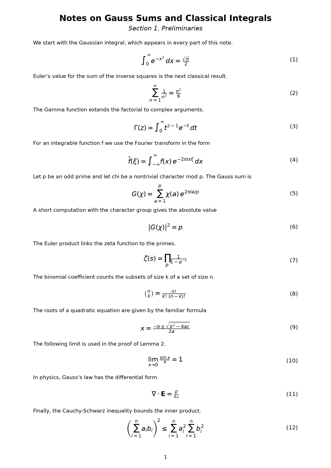

In [3]:
from PIL import Image
PAGE = "page.png"
if not os.path.exists(PAGE):   # on Colab, fetch the page from GitHub
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ParkingSoman/axiya-model-fixes/main/audit/gemma4-qat-ple/page.png", PAGE)
page = Image.open(PAGE).convert("RGB")
print("page size:", page.size)
display(page.resize((331, 468)))

In [4]:
t0 = time.time()
from transformers import AutoTokenizer
from transformers.models.gemma4.modeling_gemma4 import (
    Gemma4TextModel, Gemma4RMSNorm, Gemma4VisionModel, Gemma4MultimodalEmbedder)
from transformers.models.gemma4.configuration_gemma4 import Gemma4VisionConfig, Gemma4TextConfig
from transformers.models.gemma4.image_processing_gemma4 import Gemma4ImageProcessor

tc = ck["regular"].cfg["text_config"]
H, P, L, EPS, PAD = tc["hidden_size"], tc["hidden_size_per_layer_input"], tc["num_hidden_layers"], tc["rms_norm_eps"], tc["pad_token_id"]
assert ck["compact"].cfg["text_config"]["rms_norm_eps"] == EPS
TEXT = ("Transcribe this page to Markdown. Keep headings, paragraphs, footnotes, captions and tables. "
        "Exact wording, numbers and symbols. The proof uses the Gauss sum over the character group.")

def per_layer_part(c, mul=1.0):
    # The pieces of Gemma4TextModel that Google's code uses for the per-layer part, filled with the real tables.
    s = types.SimpleNamespace(hidden_size_per_layer_input=P, config=types.SimpleNamespace(num_hidden_layers=L),
                              per_layer_model_projection_scale=H ** -0.5, per_layer_input_scale=2.0 ** -0.5)
    s.per_layer_model_projection = nn.Linear(H, L * P, bias=False)
    s.per_layer_model_projection.weight.data = c.get(LM + "per_layer_model_projection.weight") * mul
    s.per_layer_projection_norm = Gemma4RMSNorm(P, eps=EPS)
    s.per_layer_projection_norm.weight.data = c.get(LM + "per_layer_projection_norm.weight")
    return s

def strength(s, x):
    # Share of strength kept after the normalization step: sqrt(ms / (ms + eps)). 1.0 = full strength.
    with torch.no_grad():
        pre = (s.per_layer_model_projection(x) * s.per_layer_model_projection_scale).reshape(*x.shape[:-1], L, P)
    ms = pre.pow(2).mean(-1)
    return torch.sqrt(ms / (ms + EPS)).flatten().numpy()

# Inputs: text tokens, and image tokens from the page through each model's own vision part.
tok = AutoTokenizer.from_pretrained(REGULAR)
ids = tok(TEXT, add_special_tokens=False)["input_ids"]
pc = json.loads(fs.read_text(f"{REGULAR}/processor_config.json"))["image_processor"]
pc.pop("image_processor_type", None); pc["max_soft_tokens"] = 1120
bf = Gemma4ImageProcessor(**pc)(images=[page], return_tensors="pt")
pv, pos = bf["pixel_values"][0], bf["image_position_ids"][0]
keep = (pos != -1).all(-1); pv, pos = pv[keep], pos[keep]
vcfg = Gemma4VisionConfig(**ck["regular"].cfg["vision_config"]); vcfg._attn_implementation = "sdpa"

inputs = {}
for k, c in ck.items():
    text_x = c.get(LM + "embed_tokens.weight", rows=ids) * torch.tensor(H ** 0.5)
    vt = Gemma4VisionModel(vcfg).eval()
    vt.load_state_dict({n[len("model.vision_tower."):]: c.get(n) for n in c.hdr if n.startswith("model.vision_tower.")}, strict=True)
    emb = Gemma4MultimodalEmbedder(vcfg, Gemma4TextConfig(**tc)).eval()
    emb.embedding_projection.weight.data = c.get("model.embed_vision.embedding_projection.weight")
    with torch.no_grad():
        image_x = emb(vt(pixel_values=pv[None], pixel_position_ids=pos[None]).last_hidden_state)
    inputs[k] = {"text": text_x, "image": image_x}
    del vt, emb

parts = {"regular": per_layer_part(ck["regular"]), "compact": per_layer_part(ck["compact"]), "fixed": per_layer_part(ck["compact"], FIX)}
src = {"regular": "regular", "compact": "compact", "fixed": "compact"}   # the fixed model uses the compact model's own inputs
gain = {k: {kind: strength(parts[k], inputs[src[k]][kind]) for kind in ("text", "image")} for k in parts}
print("text tokens:", len(ids), "| image tokens:", inputs["regular"]["image"].shape[0])
print(f"Part 2 time: {time.time() - t0:.0f} s")

text tokens: 36 | image tokens: 1092
Part 2 time: 57 s


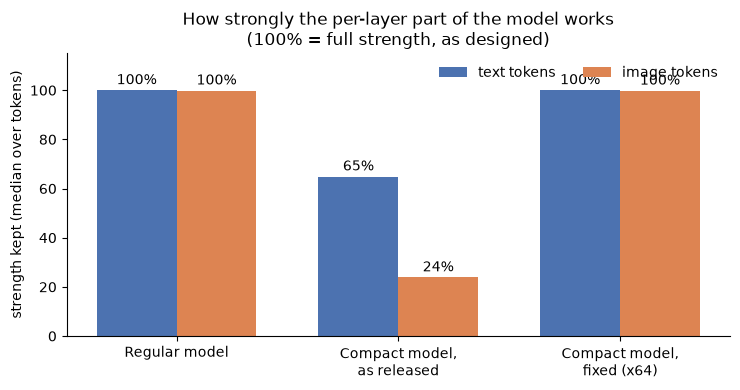

| Model | Text tokens: strength kept | Image tokens: strength kept |
|---|---|---|
| Regular model | 100.0% | 99.8% |
| Compact model, as released | 64.9% | 23.8% |
| Compact model, fixed (x64) | 100.0% | 99.8% |


In [5]:
import matplotlib.pyplot as plt
names = {"regular": "Regular model", "compact": "Compact model,\nas released", "fixed": "Compact model,\nfixed (x64)"}
med = {k: {kind: 100 * float(np.median(v)) for kind, v in g.items()} for k, g in gain.items()}

fig, ax = plt.subplots(figsize=(7.5, 4), dpi=100)
x = np.arange(3); w = 0.36
colors = {"text": "#4C72B0", "image": "#DD8452"}
for i, kind in enumerate(("text", "image")):
    vals = [med[k][kind] for k in names]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=f"{kind} tokens", color=colors[kind])
    ax.bar_label(bars, labels=[f"{v:.0f}%" for v in vals], padding=2, fontsize=10)
ax.set_xticks(x, list(names.values()))
ax.set_ylim(0, 128); ax.set_ylabel("strength kept (median over tokens)")
ax.set_title("How strongly the per-layer part of the model works\n(100% = full strength, as designed)")
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, loc="upper center", ncols=2)
plt.tight_layout(); plt.show()

t = "| Model | Text tokens: strength kept | Image tokens: strength kept |\n|---|---|---|\n"
for k, n in names.items():
    t += f"| {n.replace(chr(10), ' ')} | {med[k]['text']:.1f}% | {med[k]['image']:.1f}% |\n"
display(Markdown(t))

**How to read the chart.** Each bar is the median over all tokens and all 42 layers. In the compact model as released, the image tokens keep only about a quarter of their per-layer signal.
The change is different for each token and each layer, so the rest of the model cannot simply undo it.
Multiplying the table by 64 brings the signal back to full strength. The normalization step cancels the factor 64 itself, so the fix changes nothing else.

## Part 3 — Before and after, on real output

This part runs the full compact model on the same page, with two model files:

| Run | Model file |
|---|---|
| **As released** | Google's official 4-bit file `gemma-4-E4B_q4_0-it.gguf` from `google/gemma-4-E4B-it-qat-q4_0-gguf`, with Google's vision file `gemma-4-E4B-it-mmproj.gguf` |
| **Fixed** | A copy of the same file. The only change: the table `per_layer_model_proj.weight` is multiplied by 64 |

How it runs:

- Program: llama.cpp (release b11211), `llama-mtmd-cli`, on the Mac's GPU.
- Prompt: "Transcribe this page to Markdown. Write every formula in LaTeX."
- Greedy decoding (temperature 0, seed 0). The model always picks its most likely next word, so the output is the same on each run.
- Thinking mode off. This is the default in Google's chat template. llama.cpp turns it on unless told otherwise.
- Each file runs twice, to show that the output repeats exactly.
- Then each file runs 8 more times with random sampling (see "Sampled runs" below).

**Needs:** llama.cpp's `llama-mtmd-cli` (set `LLAMA_MTMD_CLI` to its path) and about 11 GB of free disk. Without it, this part prints a message and stops. It was not tested on Colab.

**Score.** For each output the cell counts the formulas that it wrote exactly right, out of 12, and the text lines that it wrote exactly right, out of 12.
A formula counts as right if it appears in the output with the same LaTeX as on the page. Spaces, `\,` spacing, `\left`/`\right`, `\displaystyle` and `$` signs are ignored, and `\le` = `\leq`, `\dfrac` = `\frac`.
These rules were set before the first run.
One rule was added after the first run: braces around one symbol after `_` or `^` are ignored, so `^{\infty}` = `^\infty`. Without it, the score counted the same LaTeX as wrong.
A text line counts as right if it appears word for word. The model often writes single letters such as f, p, chi, k and n as math (`$f$`, `$\chi$`), so 3 of the 12 lines do not match in either model.

In [6]:
import shutil, subprocess, re, html
t0 = time.time()
CLI = os.environ.get("LLAMA_MTMD_CLI") or shutil.which("llama-mtmd-cli")
GGUF_DIR = os.environ.get("GEMMA_GGUF_DIR", "gguf_files")
GGUF_REPO = "google/gemma-4-E4B-it-qat-q4_0-gguf"
RELEASED, MMPROJ = "gemma-4-E4B_q4_0-it.gguf", "gemma-4-E4B-it-mmproj.gguf"
FIXED = "gemma-4-E4B_q4_0-it.ple-x64.gguf"
PROMPT = "Transcribe this page to Markdown. Write every formula in LaTeX."
RUN_PART3 = CLI is not None
if not RUN_PART3:
    print("Part 3 skipped: llama-mtmd-cli was not found. Set LLAMA_MTMD_CLI to its path to run this part.")
else:
    ver = subprocess.run([CLI, "--version"], capture_output=True, text=True)
    print("llama.cpp:", [l for l in (ver.stdout + ver.stderr).splitlines() if l.startswith("version")][0])

llama.cpp: version: 0.5.0-dev (build 11211, commit d7fb90e8e)


In [7]:
if RUN_PART3:
    import gguf
    from huggingface_hub import hf_hub_download
    os.makedirs(GGUF_DIR, exist_ok=True)
    for f in (RELEASED, MMPROJ):
        if not os.path.exists(os.path.join(GGUF_DIR, f)):
            hf_hub_download(GGUF_REPO, f, local_dir=GGUF_DIR)
    rel, fix = os.path.join(GGUF_DIR, RELEASED), os.path.join(GGUF_DIR, FIXED)

    # Make the fixed copy: copy the file (a fast clone on macOS), then multiply one table by 64 in the copy.
    if not os.path.exists(fix):
        if subprocess.run(["cp", "-c", rel, fix], capture_output=True).returncode != 0:
            shutil.copyfile(rel, fix)
        r = gguf.GGUFReader(fix, mode="r+")
        t = next(t for t in r.tensors if t.name == "per_layer_model_proj.weight")
        assert gguf.GGMLQuantizationType(t.tensor_type) == gguf.GGMLQuantizationType.F16
        t.data[...] = (t.data.astype(np.float32) * FIX).astype(np.float16)
        r.data.flush(); del r

    def table_rms(path):
        r = gguf.GGUFReader(path)
        t = next(t for t in r.tensors if t.name == "per_layer_model_proj.weight")
        return float(np.sqrt((t.data.astype(np.float32) ** 2).mean()))
    print(f"per_layer_model_proj.weight RMS in the released file: {table_rms(rel):.6f}")
    print(f"per_layer_model_proj.weight RMS in the fixed copy:    {table_rms(fix):.6f}")

    # Google's chat template from the file, with thinking mode fixed to off.
    r = gguf.GGUFReader(rel); f = r.fields["tokenizer.chat_template"]
    tmpl = bytes(f.parts[f.data[0]]).decode()
    tmpl_off = tmpl.replace("{%- set enable_thinking = enable_thinking | default(false) -%}", "{%- set enable_thinking = false -%}")
    assert tmpl_off != tmpl
    del r

per_layer_model_proj.weight RMS in the released file: 0.000384


per_layer_model_proj.weight RMS in the fixed copy:    0.024573


In [8]:
GREEDY = ["--temp", "0", "--seed", "0"]
def run(model_file, sampling=GREEDY):
    cmd = [CLI, "-m", model_file, "--mmproj", os.path.join(GGUF_DIR, MMPROJ), "--image", PAGE, "-p", PROMPT,
           "--jinja", "--chat-template", tmpl_off, *sampling,
           "-n", "2048", "-c", "8192", "--image-max-tokens", "1120"]
    p = subprocess.run(cmd, capture_output=True, text=True, timeout=1200)   # keep only the model's answer (stdout)
    assert p.returncode == 0, "llama-mtmd-cli failed"
    return p.stdout.strip()

if RUN_PART3:
    outputs = {}
    for name, path in (("as released", rel), ("fixed", fix)):
        for i in (1, 2):
            s = time.time(); outputs[(name, i)] = run(path)
            print(f"{name}, run {i}: {len(outputs[(name, i)])} characters, {time.time() - s:.0f} s")
    for name in ("as released", "fixed"):
        print(f"{name}: run 1 and run 2 identical = {outputs[(name, 1)] == outputs[(name, 2)]}")

as released, run 1: 1793 characters, 24 s


as released, run 2: 1793 characters, 23 s


fixed, run 1: 1688 characters, 25 s


fixed, run 2: 1688 characters, 23 s
as released: run 1 and run 2 identical = True
fixed: run 1 and run 2 identical = True


In [9]:
import importlib.util as _u
_spec = _u.spec_from_file_location("make_page", "make_page.py") if os.path.exists("make_page.py") else None
if _spec is None:
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ParkingSoman/axiya-model-fixes/main/audit/gemma4-qat-ple/make_page.py", "make_page.py")
    _spec = _u.spec_from_file_location("make_page", "make_page.py")
mp = _u.module_from_spec(_spec); _spec.loader.exec_module(mp)

def norm(s):
    for a, b in ((r"\displaystyle", ""), (r"\left", ""), (r"\right", ""), (r"\dfrac", r"\frac"), (r"\tfrac", r"\frac"),
                 (r"\,", ""), (r"\;", ""), (r"\!", ""), (r"\leq", r"\le"), ("$", "")):
        s = s.replace(a, b)
    s = re.sub(r"\s+", "", s)
    return re.sub(r"([_^])\{(\\[A-Za-z]+|[A-Za-z0-9])\}", r"\1\2", s)   # x^{a} = x^a

def score(out):
    o, flat = norm(out), " ".join(out.split())
    return sum(norm(f) in o for f in mp.FORMULAS), sum(t in flat for t in mp.TEXT)

if RUN_PART3:
    t = "| Run | Formulas exactly right (of 12) | Text lines exactly right (of 12) |\n|---|---|---|\n"
    for (name, i), out in outputs.items():
        f_ok, t_ok = score(out)
        t += f"| {name}, run {i} | {f_ok} | {t_ok} |\n"
    display(Markdown(t))

    a, b = outputs[("as released", 1)], outputs[("fixed", 1)]
    cell = lambda s: f'<td style="vertical-align:top;text-align:left"><pre style="white-space:pre-wrap;font-size:11px">{html.escape(s)}</pre></td>'
    display(HTML('<table><tr><th style="text-align:left">Compact model, as released</th><th style="text-align:left">Compact model, fixed (one table x64)</th></tr>'
                 f"<tr>{cell(a)}{cell(b)}</tr></table>"))

| Run | Formulas exactly right (of 12) | Text lines exactly right (of 12) |
|---|---|---|
| as released, run 1 | 9 | 9 |
| as released, run 2 | 9 | 9 |
| fixed, run 1 | 10 | 9 |
| fixed, run 2 | 10 | 9 |


"Compact model, as released","Compact model, fixed (one table x64)"
"Here is the transcription of the provided text into Markdown, with all formulas rendered in LaTeX: # Notes on Gauss Sums and Classical Integrals ## Section 1. Preliminaries We start with the Gaussian integral, which appears in every part of this note. $$ \int_{0}^{\infty} e^{-x^2} dx = \sqrt{\frac{\pi}{2}} \quad (1) $$ Euler's value for the sum of the inverse squares is the next classical result. $$ \sum_{n=1}^{\infty} \frac{1}{n^2} = \frac{\pi^2}{6} \quad (2) $$ The Gamma function extends the factorial to complex arguments. $$ \Gamma(z) = \int_{0}^{\infty} t^{z-1} e^{-t} dt \quad (3) $$ For an integrable function $f$ we use the Fourier transform in the form $$ \hat{f}(\xi) = \int_{-\infty}^{\infty} f(x) e^{-2\pi i x \xi} dx \quad (4) $$ Let $p$ be an odd prime and let $\chi$ be a nontrivial character mod $p$. The Gauss sum is $$ G(\chi) = \sum_{a=1}^{p} \chi(a) e^{2\pi i a/p} \quad (5) $$ A short computation with the character group gives the absolute value $$ |G(\chi)|^2 = p \quad (6) $$ The Euler product links the zeta function to the primes. $$ \zeta(s) = \prod_{p} \frac{1}{1-p^{-s}} \quad (7) $$ The binomial coefficient counts the subsets of size $k$ of a set of size $n$. $$ \binom{n}{k} = \frac{n!}{k!(n-k)!} \quad (8) $$ The roots of a quadratic equation are given by the familiar formula $$ x = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a} \quad (9) $$ The following limit is used in the proof of Lemma 2. $$ \lim_{x \to 0} \frac{\sin x}{x} = 1 \quad (10) $$ In physics, Gauss's law has the differential form $$ \nabla \cdot \mathbf{E} = \frac{\rho}{\epsilon_0} \quad (11) $$ Finally, the Cauchy-Schwarz inequality bounds the inner product. $$ \left( \sum_{i=1}^{n} a_i b_i \right)^2 \le \left( \sum_{i=1}^{n} a_i^2 \right) \left( \sum_{i=1}^{n} b_i^2 \right) \quad (12) $$","# Notes on Gauss Sums and Classical Integrals ## Section 1. Preliminaries We start with the Gaussian integral, which appears in every part of this note. $$ \int_0^\infty e^{-x^2} dx = \sqrt{\frac{\pi}{2}} \quad (1) $$ Euler's value for the sum of the inverse squares is the next classical result. $$ \sum_{n=1}^\infty \frac{1}{n^2} = \frac{\pi^2}{6} \quad (2) $$ The Gamma function extends the factorial to complex arguments. $$ \Gamma(z) = \int_0^\infty t^{z-1} e^{-t} dt \quad (3) $$ For an integrable function $f$ we use the Fourier transform in the form $$ \hat{f}(\xi) = \int_{-\infty}^\infty f(x) e^{-2\pi i x \xi} dx \quad (4) $$ Let $p$ be an odd prime and let $\chi$ be a nontrivial character mod $p$. The Gauss sum is $$ G(\chi) = \sum_{a=1}^p \chi(a) e^{2\pi i a/p} \quad (5) $$ A short computation with the character group gives the absolute value $$ |G(\chi)|^2 = p \quad (6) $$ The Euler product links the zeta function to the primes. $$ \zeta(s) = \prod_p \frac{1}{1-p^{-s}} \quad (7) $$ The binomial coefficient counts the subsets of size $k$ of a set of size $n$. $$ \binom{n}{k} = \frac{n!}{k!(n-k)!} \quad (8) $$ The roots of a quadratic equation are given by the familiar formula $$ x = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a} \quad (9) $$ The following limit is used in the proof of Lemma 2. $$ \lim_{x \to 0} \frac{\sin x}{x} = 1 \quad (10) $$ In physics, Gauss's law has the differential form $$ \nabla \cdot \mathbf{E} = \frac{\rho}{\varepsilon_0} \quad (11) $$ Finally, the Cauchy-Schwarz inequality bounds the inner product. $$ \left( \sum_{i=1}^n a_i b_i \right)^2 \le \left( \sum_{i=1}^n a_i^2 \right) \left( \sum_{i=1}^n b_i^2 \right) \quad (12) $$ 1"


In [10]:
if RUN_PART3:
    # Per formula: which ones each model wrote exactly right (run 1).
    t = "| # | Formula on the page | As released | Fixed |\n|---|---|---|---|\n"
    for i, f in enumerate(mp.FORMULAS, 1):
        ok = [("yes" if norm(f) in norm(outputs[(n, 1)]) else "no") for n in ("as released", "fixed")]
        t += f"| {i} | `{f}` | {ok[0]} | {ok[1]} |\n"
    display(Markdown(t))

| # | Formula on the page | As released | Fixed |
|---|---|---|---|
| 1 | `\int_0^\infty e^{-x^2}\,dx = \frac{\sqrt{\pi}}{2}` | no | no |
| 2 | `\sum_{n=1}^{\infty} \frac{1}{n^2} = \frac{\pi^2}{6}` | yes | yes |
| 3 | `\Gamma(z) = \int_0^\infty t^{z-1} e^{-t}\,dt` | yes | yes |
| 4 | `\hat{f}(\xi) = \int_{-\infty}^{\infty} f(x)\, e^{-2\pi i x \xi}\,dx` | yes | yes |
| 5 | `G(\chi) = \sum_{a=1}^{p} \chi(a)\, e^{2\pi i a/p}` | yes | yes |
| 6 | `|G(\chi)|^2 = p` | yes | yes |
| 7 | `\zeta(s) = \prod_{p} \frac{1}{1 - p^{-s}}` | yes | yes |
| 8 | `\binom{n}{k} = \frac{n!}{k!\,(n-k)!}` | yes | yes |
| 9 | `x = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a}` | yes | yes |
| 10 | `\lim_{x \to 0} \frac{\sin x}{x} = 1` | yes | yes |
| 11 | `\nabla \cdot \mathbf{E} = \frac{\rho}{\varepsilon_0}` | no | yes |
| 12 | `\left(\sum_{i=1}^{n} a_i b_i\right)^2 \leq \sum_{i=1}^{n} a_i^2 \sum_{i=1}^{n} b_i^2` | no | no |


### Sampled runs

This step was added after the greedy runs above. It uses the sampling settings of the bug report's page test:
temperature 1, top_k 64, top_p 0.95, min_p 0.05. Each file runs 8 times, with seeds 1 to 8. Both files use the same seeds.
The cell counts formulas and text lines with the same rules as above, out of 96 each (12 per run x 8 runs).

In [11]:
if RUN_PART3:
    SEEDS = range(1, 9)
    sampled = {}
    for name, path in (("as released", rel), ("fixed", fix)):
        for sd in SEEDS:
            sampled[(name, sd)] = run(path, ["--temp", "1", "--top-k", "64", "--top-p", "0.95", "--min-p", "0.05", "--seed", str(sd)])
    t = "| Seed | As released: formulas | Fixed: formulas | As released: text lines | Fixed: text lines |\n|---|---|---|---|---|\n"
    tot = {"as released": [0, 0], "fixed": [0, 0]}
    for sd in SEEDS:
        a, b = score(sampled[("as released", sd)]), score(sampled[("fixed", sd)])
        for n, v in (("as released", a), ("fixed", b)):
            tot[n][0] += v[0]; tot[n][1] += v[1]
        t += f"| {sd} | {a[0]}/12 | {b[0]}/12 | {a[1]}/12 | {b[1]}/12 |\n"
    n = 12 * len(SEEDS)
    t += f"| **Total** | **{tot['as released'][0]}/{n}** | **{tot['fixed'][0]}/{n}** | **{tot['as released'][1]}/{n}** | **{tot['fixed'][1]}/{n}** |\n"
    display(Markdown(t))
    print(f"Part 3 time: {time.time() - t0:.0f} s")
print(f"Whole notebook: {time.time() - T_START:.0f} s")

| Seed | As released: formulas | Fixed: formulas | As released: text lines | Fixed: text lines |
|---|---|---|---|---|
| 1 | 7/12 | 7/12 | 8/12 | 0/12 |
| 2 | 7/12 | 8/12 | 0/12 | 9/12 |
| 3 | 10/12 | 7/12 | 8/12 | 9/12 |
| 4 | 7/12 | 10/12 | 9/12 | 9/12 |
| 5 | 11/12 | 11/12 | 9/12 | 9/12 |
| 6 | 8/12 | 10/12 | 9/12 | 9/12 |
| 7 | 7/12 | 11/12 | 8/12 | 9/12 |
| 8 | 9/12 | 10/12 | 8/12 | 9/12 |
| **Total** | **66/96** | **74/96** | **59/96** | **63/96** |


Part 3 time: 610 s
Whole notebook: 669 s


### What Part 3 shows

- On this clean, computer-drawn page, both files read most of the page. The two outputs are nearly the same.
- Greedy runs: the fixed file wrote 10 of 12 formulas exactly right, the released file 9. The only difference is formula 11. The released file wrote `\epsilon` where the page has `\varepsilon`. Both files make the same mistakes in formulas 1 and 12.
- Sampled runs: the fixed file wrote 74 of 96 formulas exactly right, the released file 66. The scores change much from seed to seed, so 8 runs per file are too few to call this gap reliable.
- A text score of 0 means that the model wrote only the formulas and left out the text.
- On this page, the fix did not make the output worse.
- The bug report shows a larger gap on a real scanned page, with the same sampling settings: 14 of 96 formulas right as released, 54 of 96 fixed. That page is not public, so it is not in this notebook.

The clear evidence of the bug is in Parts 1 and 2. On an easy page like this one, the visible gain from the fix is small.

## Summary

| | Source |
|---|---|
| The table is about 64 times smaller in the compact model | Part 1: read directly from Google's files |
| This weakens the per-layer part of the model, most on images | Part 2: Google's own model code, run on the real tables |
| Multiplying the table by 64 restores it | Parts 1 and 2: the same Google file, multiplied by 64 |
| On this clean page, the fixed file reads slightly better: 10 against 9 formulas (greedy), 74 against 66 of 96 (sampled). The gap is small and not proven by so few runs | Part 3: llama.cpp, Google's official 4-bit file and a copy with one table x64 |

More detail: [`BUG_REPORT.txt`](BUG_REPORT.txt). Command-line check: [`repro_ple_eps.py`](repro_ple_eps.py).
Report filed with Google: https://huggingface.co/google/gemma-4-E4B-it-qat-q4_0-unquantized/discussions/7